# SVG ID-Only Automatic Inference Demo

This notebook shows whether the matrix inference layer can recover activity groups, candidate regions, and gap paths from the three ID-only probe SVGs after manual region/path marks are removed.

## 1. Probe SVGs

In [1]:
from pathlib import Path

svg_fixture_paths = sorted(Path("test").glob("SVG*.svg"))
[path.name for path in svg_fixture_paths]

['SVG_baseline.svg', 'SVG_chaoticsvg.svg', 'SVG_oblique.svg']

## 2. Automatic Inference Summary

In [2]:
from pathlib import Path
from features import load_structured_svg_scene
from features.scene_inference import infer_scene_evidence

svg_fixture_paths = sorted(Path("test").glob("SVG*.svg"))
svg_fixture_summaries = []
for svg_path in svg_fixture_paths:
    scene = load_structured_svg_scene(svg_path)
    evidence = infer_scene_evidence(scene)
    svg_fixture_summaries.append({
        "file": svg_path.name,
        "objects": len(scene["objects"]),
        "manual_regions": len(scene["regions"]),
        "manual_paths": len(scene["paths"]),
        "activity_groups": len(evidence["activity_groups"]),
        "inferred_candidates": len(evidence["inferred_region_candidates"]),
        "inferred_gap_paths": len(evidence["inferred_region_gap_paths"]),
    })

svg_fixture_summaries


[{'file': 'SVG_baseline.svg',
  'objects': 44,
  'manual_regions': 0,
  'manual_paths': 0,
  'activity_groups': 5,
  'inferred_candidates': 5,
  'inferred_gap_paths': 7},
 {'file': 'SVG_chaoticsvg.svg',
  'objects': 44,
  'manual_regions': 0,
  'manual_paths': 0,
  'activity_groups': 5,
  'inferred_candidates': 5,
  'inferred_gap_paths': 7},
 {'file': 'SVG_oblique.svg',
  'objects': 44,
  'manual_regions': 0,
  'manual_paths': 0,
  'activity_groups': 5,
  'inferred_candidates': 5,
  'inferred_gap_paths': 5}]

## 3. Inference Overlays


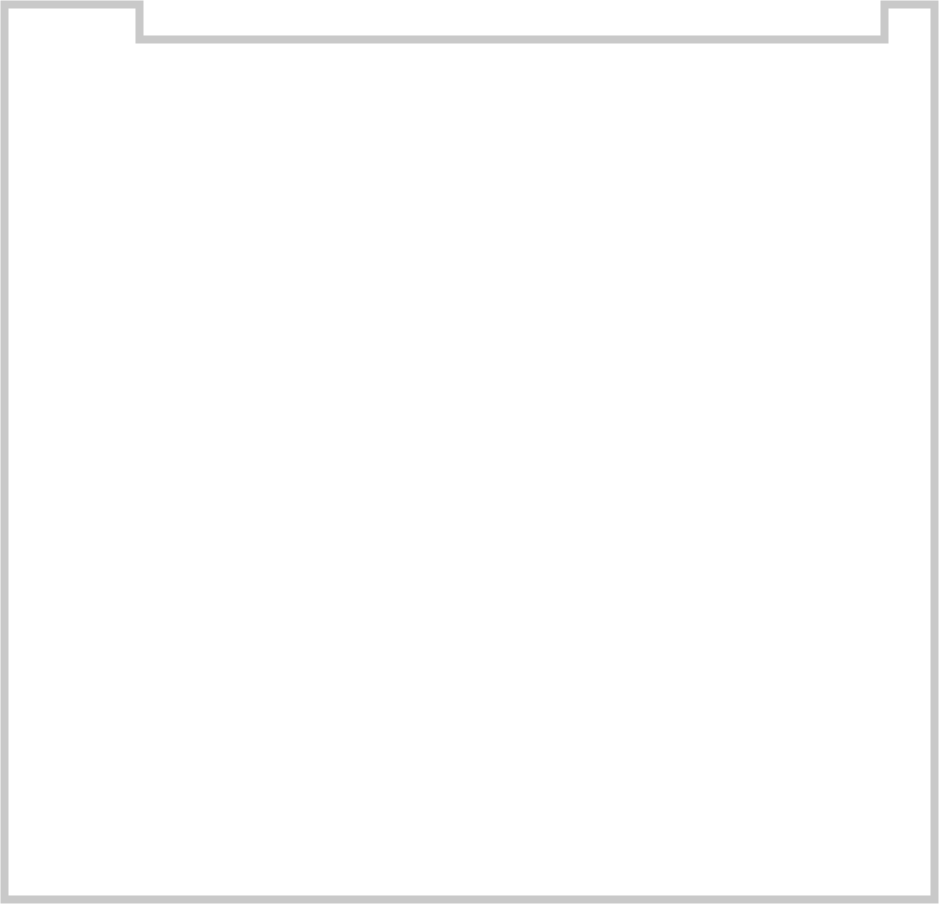
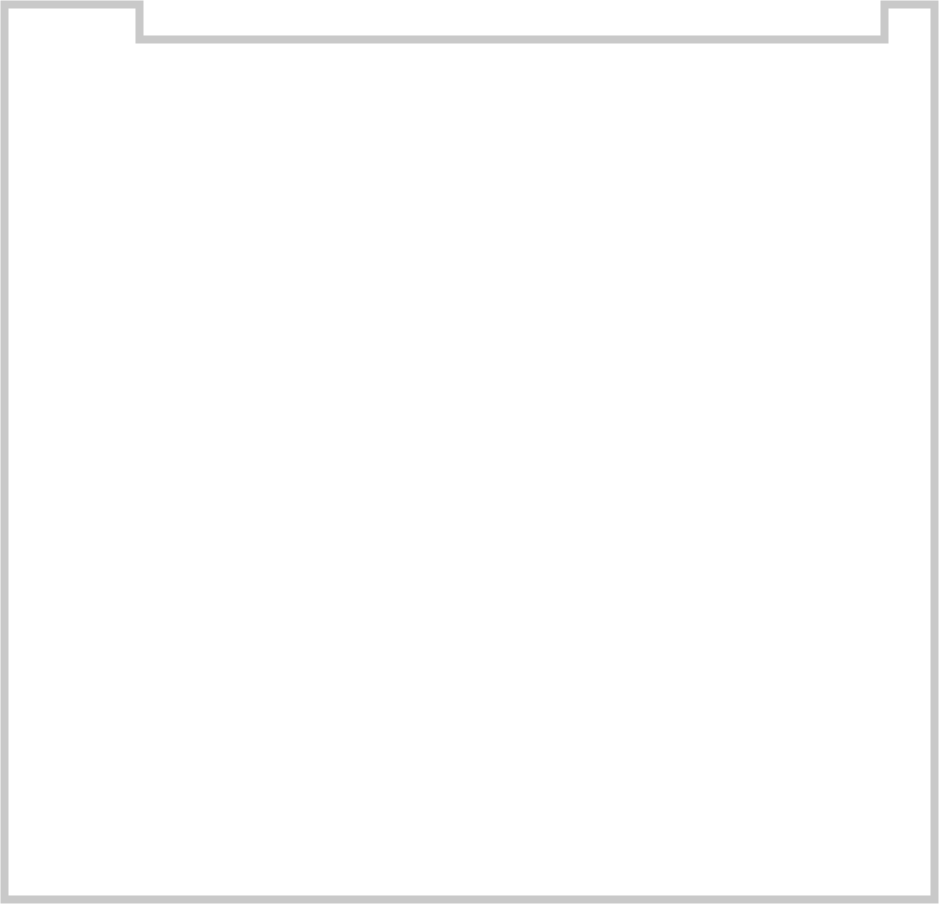
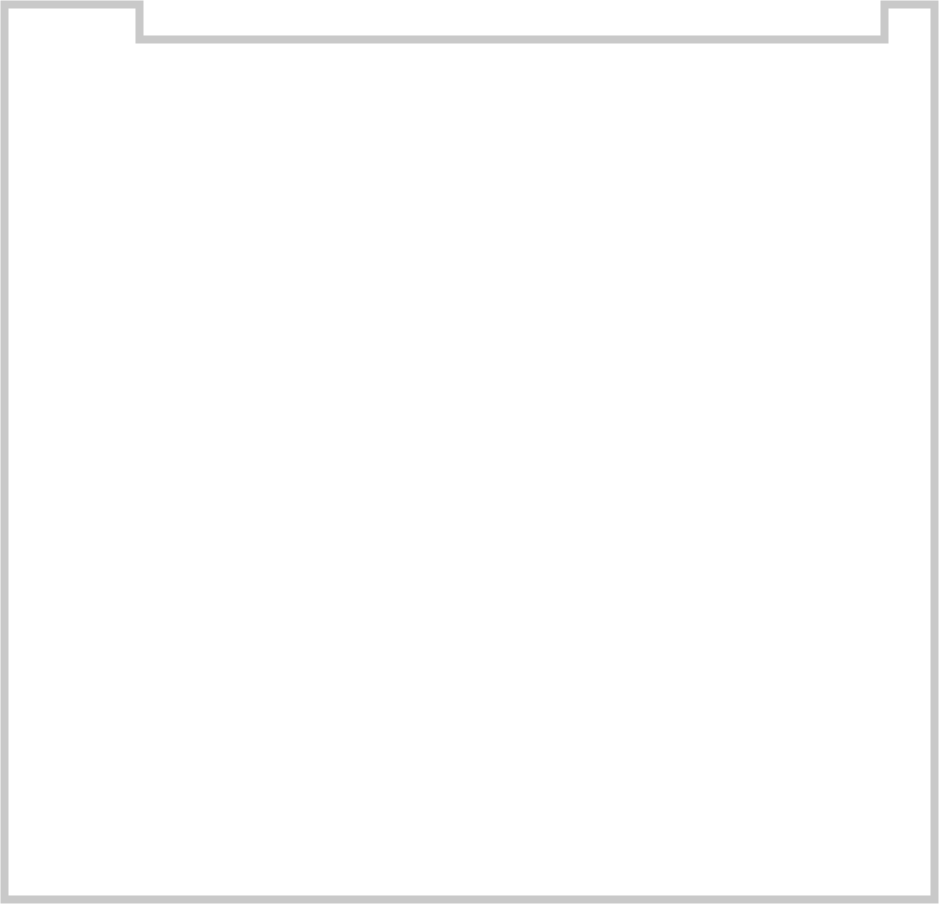

In [3]:
from html import escape
from IPython.display import HTML, display
from features.scene_evaluator import _axis_line, _record_axis_descriptor


def _rect_svg(rect, attrs, style):
    """Render one Rect as an SVG rectangle for notebook diagnostics."""
    return (
        f'<rect {attrs} x="{rect.left:.1f}" y="{rect.top:.1f}" '
        f'width="{rect.width:.1f}" height="{rect.height:.1f}" {style}/>'
    )


def _inference_overlay_html(svg_path):
    """Render the source SVG with automatic inference overlays for visual QA."""
    scene = load_structured_svg_scene(svg_path)
    evidence = infer_scene_evidence(scene)
    width, height = scene["size"]
    layers = []
    for group in evidence["activity_groups"]:
        rect = group["rect"]
        layers.append(
            _rect_svg(
                rect,
                f'data-layer="activity-group" data-id="{escape(group["id"])}"',
                'fill="none" stroke="#ef4444" stroke-width="3" stroke-dasharray="8 6" opacity="0.85"',
            )
        )
        layers.append(
            f'<text x="{rect.left:.1f}" y="{rect.top - 8:.1f}" '
            f'font-size="18" fill="#ef4444">{escape(group["region"])}</text>'
        )
    for region in evidence["inferred_region_candidates"]:
        rect = region["rect"]
        layers.append(
            _rect_svg(
                rect,
                f'data-layer="inferred-region-candidate" data-id="{escape(region["id"])}"',
                'fill="#38bdf8" opacity="0.08" stroke="#0284c7" stroke-width="2.5"',
            )
        )
        # Draw the region's inferred trend axis from the same descriptor used by the matrix overlay.
        axis = _record_axis_descriptor(region)
        x1, y1, x2, y2 = _axis_line(rect, axis["angle"])
        layers.append(
            f'<line data-layer="region-trend" data-region="{escape(region["id"])}" '
            f'data-angle="{axis["angle"]:.4f}" data-basis="{escape(axis["basis"])}" '
            f'x1="{x1:.1f}" y1="{y1:.1f}" x2="{x2:.1f}" y2="{y2:.1f}" '
            f'stroke="#f97316" stroke-width="4" stroke-linecap="round" opacity="0.9">'
            f'<title>{escape(region["id"])} trend {axis["angle"]:.1f} deg ({escape(axis["basis"])})</title>'
            f'</line>'
        )
    for path in evidence["inferred_region_gap_paths"]:
        layers.append(
            _rect_svg(
                path["rect"],
                f'data-layer="inferred-gap-path" data-id="{escape(path["id"])}"',
                'fill="#a78bfa" opacity="0.20" stroke="#7c3aed" stroke-width="2"',
            )
        )
    original = svg_path.read_text(encoding="utf-8")
    return f"""
<div style='font:14px Arial;margin:12px 0;color:#334155'>
{escape(svg_path.name)} | objects={len(scene['objects'])} | groups={len(evidence['activity_groups'])} | candidates={len(evidence['inferred_region_candidates'])} | gap_paths={len(evidence['inferred_region_gap_paths'])}
</div>
<div style='position:relative;width:min(96vw,1000px);aspect-ratio:1/1;border:1px solid #cbd5e1;background:white;margin-bottom:24px'>
{original}
<svg viewBox='0 0 {width:g} {height:g}' xmlns='http://www.w3.org/2000/svg' style='position:absolute;inset:0;width:100%;height:100%'>
{''.join(layers)}
</svg>
</div>
"""


display(HTML("".join(_inference_overlay_html(path) for path in svg_fixture_paths)))
